# Week 12: Hybrid Retrieval and Bookend Ordering (Demo)

This notebook demonstrates Hybrid Retrieval (BM25 + Dense FAISS) and context ordering strategies to address the 'Lost in the Middle' problem. No pipeline wrappers (like LangChain) are used here; we build the core math and logic manually to understand the underlying mechanics.

In [1]:
# Required Libraries
# sentence-transformers>=2.6.0
# rank-bm25>=0.2.2
# faiss-cpu>=1.7.4
# numpy>=1.24.0
# torch>=2.0.0
# transformers>=4.37.0
# matplotlib>=3.7.0
# seaborn>=0.12.0
# tqdm>=4.65.0


## Part 1: Hybrid Retrieval

In [2]:
# ═══════════════════════════════════════════
# SECTION 1: Corpus Setup
# Theory: We need a diverse corpus to demonstrate vocabulary mismatch.
# What this cell does: Loads 30 Wikipedia-style paragraphs across 3 topics.
# ═══════════════════════════════════════════

CORPUS = [
    # Topic A: Machine Learning
    "Machine learning focuses on the development of computer programs that can access data and use it to learn for themselves.",
    "Supervised learning is a machine learning paradigm for acquiring the input-output relationship from training data.",
    "Unsupervised learning is a type of machine learning that looks for previously undetected patterns in a data set with no pre-existing labels.",
    "Reinforcement learning is an area of machine learning concerned with how software agents ought to take actions in an environment.",
    "Deep learning is part of a broader family of machine learning methods based on artificial neural networks with representation learning.",
    "Gradient descent is a first-order iterative optimization algorithm for finding a local minimum of a differentiable function.",
    "Overfitting is a modeling error that occurs when a function is too closely fit to a limited set of data points.",
    "Cross-validation is a resampling method that uses different portions of the data to test and train a model on different iterations.",
    "A neural network is a network or circuit of biological neurons, or, in a modern sense, an artificial neural network.",
    "Natural language processing is a subfield of linguistics, computer science, and artificial intelligence concerned with the interactions between computers and human language.",
    
    # Topic B: Cardiac Medicine
    "Cardiac medicine deals with disorders of the heart as well as some parts of the circulatory system.",
    "A myocardial infarction, commonly known as a heart attack, occurs when blood flow decreases or stops to the coronary artery of the heart.",
    "Coronary artery disease is the most common of the cardiovascular diseases and is a major cause of death globally.",
    "Echocardiography uses standard two-dimensional, three-dimensional, and Doppler ultrasound to create images of the heart.",
    "An electrocardiogram (ECG) is a graph of voltage versus time of the electrical activity of the heart using electrodes placed on the skin.",
    "Heart failure occurs when the heart is unable to pump sufficiently to maintain blood flow to meet the body's needs.",
    "Atrial fibrillation is an abnormal heart rhythm characterized by rapid and irregular beating of the atria.",
    "Cardiac arrest is a sudden loss of blood flow resulting from the failure of the heart to pump effectively.",
    "Hypertension, also known as high blood pressure, is a long-term medical condition in which the blood pressure in the arteries is persistently elevated.",
    "Cholesterol is a lipid molecule and is biosynthesized by all animal cells because it is an essential structural component of all animal cell membranes.",
    
    # Topic C: Contract Law
    "Contract law is the body of law that relates to making and enforcing agreements.",
    "A breach of contract is a legal cause of action and a type of civil wrong, in which a binding agreement or bargained-for exchange is not honored.",
    "Consideration is a concept of English common law and is a necessity for simple contracts, but not for special contracts.",
    "An offer is a statement of the terms on which the offeror is willing to be bound.",
    "Acceptance in contract law is the unconditional agreement to the terms of an offer.",
    "A void contract cannot be enforced by law, meaning it is not a contract at all.",
    "A voidable contract is a valid contract which may be either affirmed or rejected at the option of one of the parties.",
    "Damages are an award, typically of money, to be paid to a person as compensation for loss or injury.",
    "Specific performance is an equitable remedy in the law of contract, whereby a court issues an order requiring a party to perform a specific act.",
    "A force majeure clause is a contract provision that allows a party to suspend or terminate the performance of its obligations when certain circumstances beyond their control arise."
]

print(f"Corpus loaded: {len(CORPUS)} documents across 3 topics")

Corpus loaded: 30 documents across 3 topics


In [3]:
# ═══════════════════════════════════════════
# SECTION 2: BM25 Indexing
# Theory: BM25 scores documents based on term frequency (TF) and inverse document frequency (IDF), with saturation.
# - IDF penalizes words that appear in many documents.
# - TF Saturation ensures that a word appearing 10 times isn't 10x more important than appearing 1 time.
# What this cell does: Tokenizes the corpus and builds a BM25Okapi index.
# ═══════════════════════════════════════════

from rank_bm25 import BM25Okapi

# Basic whitespace tokenization
tokenized_corpus = [doc.lower().split() for doc in CORPUS]
bm25 = BM25Okapi(tokenized_corpus)

print(f"BM25 index built over vocabulary of {len(bm25.idf)} unique terms")

BM25 index built over vocabulary of 307 unique terms


In [4]:
# ═══════════════════════════════════════════
# SECTION 3: BM25 Retrieval Demo
# Theory: Lexical search relies on exact keyword matches.
# What this cell does: Retrieves top 10 documents for "heart attack treatment".
# ═══════════════════════════════════════════

query = "heart attack treatment"
scores = bm25.get_scores(query.lower().split())
# Sort by score descending
bm25_results = sorted(enumerate(scores), key=lambda x: x[1], reverse=True)[:10]

print(f"BM25 Top-10 Results for query: '{query}'\n")
for rank, (doc_idx, score) in enumerate(bm25_results):
    topic = "ML" if doc_idx < 10 else "Medicine" if doc_idx < 20 else "Law"
    print(f"Rank {rank+1} | Score: {score:.3f} | Topic: {topic:8s} | {CORPUS[doc_idx][:60]}...")
    
# Notice: the one document that literally says "heart attack" (Doc 11, myocardial infarction) only ranks 5th —
# BM25 rewards the repeated token "heart" (Heart failure, Doc 15) over the actual synonym match.

BM25 Top-10 Results for query: 'heart attack treatment'

Rank 1 | Score: 1.893 | Topic: Medicine | Heart failure occurs when the heart is unable to pump suffic...
Rank 2 | Score: 1.456 | Topic: Medicine | Atrial fibrillation is an abnormal heart rhythm characterize...
Rank 3 | Score: 1.421 | Topic: Medicine | Cardiac medicine deals with disorders of the heart as well a...
Rank 4 | Score: 1.355 | Topic: Medicine | Cardiac arrest is a sudden loss of blood flow resulting from...
Rank 5 | Score: 1.241 | Topic: Medicine | A myocardial infarction, commonly known as a heart attack, o...
Rank 6 | Score: 1.241 | Topic: Medicine | An electrocardiogram (ECG) is a graph of voltage versus time...
Rank 7 | Score: 0.000 | Topic: ML       | Machine learning focuses on the development of computer prog...
Rank 8 | Score: 0.000 | Topic: ML       | Supervised learning is a machine learning paradigm for acqui...
Rank 9 | Score: 0.000 | Topic: ML       | Unsupervised learning is a type of machine learning t

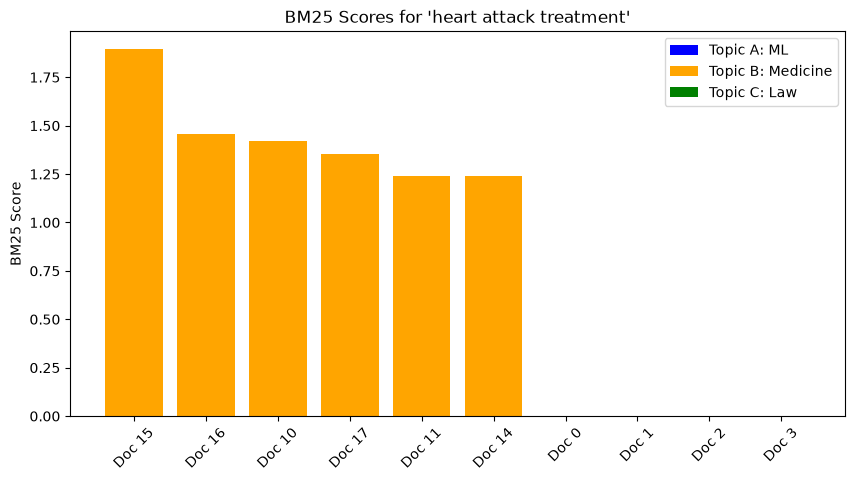

In [5]:
# ═══════════════════════════════════════════
# SECTION 4: Vocabulary Mismatch Visualization
# Theory: Visualizing the score distribution highlights lexical gaps.
# What this cell does: Plots a bar chart of top BM25 scores with topic color-coding.
# ═══════════════════════════════════════════
import matplotlib.pyplot as plt

doc_indices = [x[0] for x in bm25_results]
doc_scores = [x[1] for x in bm25_results]
colors = ['blue' if idx < 10 else 'orange' if idx < 20 else 'green' for idx in doc_indices]

plt.figure(figsize=(10, 5))
plt.bar(range(1, 11), doc_scores, color=colors)
plt.xticks(range(1, 11), [f"Doc {idx}" for idx in doc_indices], rotation=45)
plt.ylabel("BM25 Score")
plt.title("BM25 Scores for 'heart attack treatment'")

# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='blue', label='Topic A: ML'),
                   Patch(facecolor='orange', label='Topic B: Medicine'),
                   Patch(facecolor='green', label='Topic C: Law')]
plt.legend(handles=legend_elements)
plt.show()

In [6]:
# ═══════════════════════════════════════════
# SECTION 5: Dense Embedding Model Load
# Theory: Bi-Encoder architectures use independent neural towers to embed queries and documents into a shared vector space.
#   Advantage: Document embeddings can be precomputed offline.
# What this cell does: Loads a pre-trained SentenceTransformer model.
# ═══════════════════════════════════════════
from sentence_transformers import SentenceTransformer

model = SentenceTransformer('all-MiniLM-L6-v2')
print(f"Model embedding dimension: {model.get_sentence_embedding_dimension()}")  # Expected: 384

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model embedding dimension: 384


/var/folders/y5/tvzvp5ss5_v53kbw81sl6dcr0000gn/T/ipykernel_20808/2289419487.py:10: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Model embedding dimension: {model.get_sentence_embedding_dimension()}")  # Expected: 384


In [7]:
# ═══════════════════════════════════════════
# SECTION 6: Corpus Embedding
# Theory: Vectors encode semantic meaning rather than exact words.
# What this cell does: Encodes the entire corpus into dense vectors.
# ═══════════════════════════════════════════
import numpy as np
import time

t0 = time.time()
corpus_embeddings = model.encode(CORPUS, show_progress_bar=True, normalize_embeddings=True)
t1 = time.time()

print(f"corpus_embeddings shape: {corpus_embeddings.shape}")  # Expected: [30, 384]
print(f"Embedding time: {t1-t0:.2f}s — this is OFFLINE (one-time cost)")

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

corpus_embeddings shape: (30, 384)
Embedding time: 0.12s — this is OFFLINE (one-time cost)


In [8]:
# ═══════════════════════════════════════════
# SECTION 7: FAISS Index Construction
# Theory: FAISS IndexFlatIP performs exhaustive inner product search. Since our vectors are normalized, 
#   inner product is mathematically equivalent to cosine similarity.
#   (For production with millions of docs, we would switch to IndexIVFFlat or HNSW).
# What this cell does: Builds a FAISS index over the corpus embeddings.
# ═══════════════════════════════════════════
import faiss

d = corpus_embeddings.shape[1]  # 384
index = faiss.IndexFlatIP(d)    # Inner Product (cosine after L2 norm)
index.add(corpus_embeddings.astype(np.float32))

print(f"FAISS index: {index.ntotal} vectors indexed, dimension={d}")
 
# Best Practice: Persist the index to disk to avoid re-computing
faiss.write_index(index, 'demo_vector.index')
print("Index saved to 'demo_vector.index'")

# Simulate loading the index back for production inference
loaded_index = faiss.read_index('demo_vector.index')
print(f"Loaded index has {loaded_index.ntotal} vectors")

FAISS index: 30 vectors indexed, dimension=384
Index saved to 'demo_vector.index'
Loaded index has 30 vectors


In [9]:
# ═══════════════════════════════════════════
# SECTION 8: Dense Retrieval Demo
# Theory: Dense retrieval bridges the vocabulary gap (e.g., matching "heart attack" with "myocardial infarction").
#   (Cardiac arrest is a different condition medically — it ranks high here only because it is semantically adjacent.)
# What this cell does: Searches the FAISS index for the same query.
# ═══════════════════════════════════════════

query_emb = model.encode([query], normalize_embeddings=True).astype(np.float32)
print(f"query_emb shape: {query_emb.shape}")  # [1, 384]

D, I = index.search(query_emb, k=10)

print(f"Dense Top-10 Results for query: '{query}'\n")
for rank, (doc_idx, score) in enumerate(zip(I[0], D[0])):
    topic = "ML" if doc_idx < 10 else "Medicine" if doc_idx < 20 else "Law"
    print(f"Rank {rank+1} | Score: {score:.3f} | Topic: {topic:8s} | {CORPUS[doc_idx][:60]}...")
    
# Notice: Now medical documents containing synonyms or related concepts rank highly!

query_emb shape: (1, 384)
Dense Top-10 Results for query: 'heart attack treatment'

Rank 1 | Score: 0.541 | Topic: Medicine | A myocardial infarction, commonly known as a heart attack, o...
Rank 2 | Score: 0.524 | Topic: Medicine | Cardiac medicine deals with disorders of the heart as well a...
Rank 3 | Score: 0.419 | Topic: Medicine | Cardiac arrest is a sudden loss of blood flow resulting from...
Rank 4 | Score: 0.393 | Topic: Medicine | Heart failure occurs when the heart is unable to pump suffic...
Rank 5 | Score: 0.305 | Topic: Medicine | Coronary artery disease is the most common of the cardiovasc...
Rank 6 | Score: 0.284 | Topic: Medicine | Atrial fibrillation is an abnormal heart rhythm characterize...
Rank 7 | Score: 0.266 | Topic: Medicine | Echocardiography uses standard two-dimensional, three-dimens...
Rank 8 | Score: 0.207 | Topic: Medicine | Hypertension, also known as high blood pressure, is a long-t...
Rank 9 | Score: 0.188 | Topic: Medicine | An electrocardiogram (ECG)

In [10]:
# ═══════════════════════════════════════════
# SECTION 9: Side-by-Side Comparison Visualization
# Theory: BM25 and Dense Retrieval often fetch different sets of documents. 
# What this cell does: Compares the top-5 documents from both methods.
# ═══════════════════════════════════════════

print(f"Query: '{query}'\n")
print(f"{'Rank':<5} | {'BM25 Result (Doc Index)':<25} | {'Dense Result (Doc Index)':<25}")
print("-" * 65)
for i in range(5):
    bm25_idx = bm25_results[i][0]
    dense_idx = I[0][i]
    
    # Add topic labels
    bm25_topic = "ML" if bm25_idx < 10 else "Medicine" if bm25_idx < 20 else "Law"
    dense_topic = "ML" if dense_idx < 10 else "Medicine" if dense_idx < 20 else "Law"
    
    print(f"{i+1:<5} | Doc {bm25_idx:<3} ({bm25_topic:<8})            | Doc {dense_idx:<3} ({dense_topic:<8})")

Query: 'heart attack treatment'

Rank  | BM25 Result (Doc Index)   | Dense Result (Doc Index) 
-----------------------------------------------------------------
1     | Doc 15  (Medicine)            | Doc 11  (Medicine)
2     | Doc 16  (Medicine)            | Doc 10  (Medicine)
3     | Doc 10  (Medicine)            | Doc 17  (Medicine)
4     | Doc 17  (Medicine)            | Doc 15  (Medicine)
5     | Doc 11  (Medicine)            | Doc 12  (Medicine)


BM25 score range: 0.000 to 1.893
Dense score range: 0.136 to 0.541
Conclusion: We cannot add these scores directly because they reside on entirely different numerical scales!


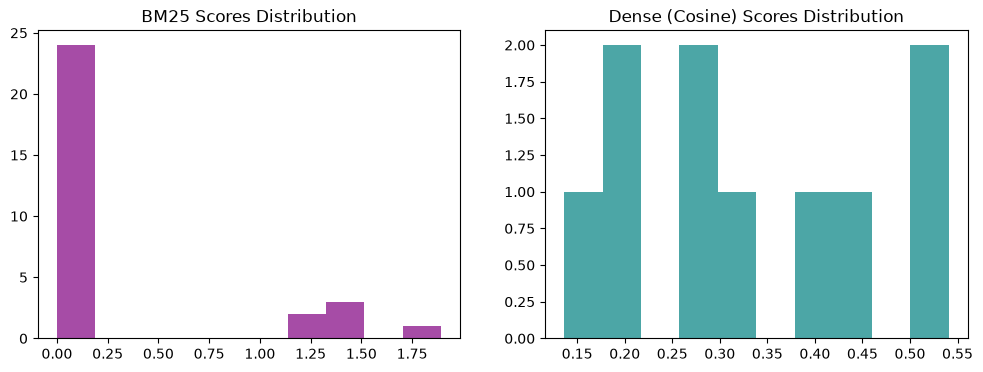

In [11]:
# ═══════════════════════════════════════════
# SECTION 10: Score Distribution Problem
# Theory: BM25 scores are unbounded and tf-idf dependent. Cosine similarity is bounded [-1, 1].
# What this cell does: Shows why we can't simply add BM25 scores to Dense scores.
# ═══════════════════════════════════════════

print(f"BM25 score range: {min(scores):.3f} to {max(scores):.3f}")
print(f"Dense score range: {D[0].min():.3f} to {D[0].max():.3f}")
print("Conclusion: We cannot add these scores directly because they reside on entirely different numerical scales!")

# Quick Histogram Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.hist(scores, bins=10, color='purple', alpha=0.7)
ax1.set_title("BM25 Scores Distribution")
ax2.hist(D[0], bins=10, color='teal', alpha=0.7)
ax2.set_title("Dense (Cosine) Scores Distribution")
plt.show()

In [12]:
# ═══════════════════════════════════════════
# SECTION 11: RRF Implementation from Scratch
# Theory: Reciprocal Rank Fusion combines rankings gracefully without score normalization.
# What this cell does: Implements RRF and runs it on our two result lists.
# ═══════════════════════════════════════════

def rrf_merge(results_list: list[list[int]], k: int = 60) -> list[tuple[int, float]]:
    """
    Reciprocal Rank Fusion.
    Args:
        results_list: list of ranked document index lists (each already sorted by relevance)
        k: smoothing constant (default=60, from Cormack et al. 2009)
    Returns:
        List of (doc_idx, rrf_score) sorted by rrf_score descending
    """
    from collections import defaultdict
    scores = defaultdict(float)
    for ranked_list in results_list:
        for rank, doc_idx in enumerate(ranked_list):
            # rank is 0-indexed; add 1 to get 1-indexed rank
            scores[doc_idx] += 1.0 / (k + rank + 1)
    return sorted(scores.items(), key=lambda x: x[1], reverse=True)

# Run RRF
bm25_order = [idx for idx, _ in bm25_results]
dense_order = I[0].tolist()
rrf_results = rrf_merge([bm25_order, dense_order], k=60)

print("RRF Top-10:")
for rank, (doc_idx, score) in enumerate(rrf_results[:10]):
    print(f"  Rank {rank+1}: doc[{doc_idx}] score={score:.5f} | {CORPUS[doc_idx][:60]}...")

RRF Top-10:
  Rank 1: doc[15] score=0.03202 | Heart failure occurs when the heart is unable to pump suffic...
  Rank 2: doc[10] score=0.03200 | Cardiac medicine deals with disorders of the heart as well a...
  Rank 3: doc[11] score=0.03178 | A myocardial infarction, commonly known as a heart attack, o...
  Rank 4: doc[17] score=0.03150 | Cardiac arrest is a sudden loss of blood flow resulting from...
  Rank 5: doc[16] score=0.03128 | Atrial fibrillation is an abnormal heart rhythm characterize...
  Rank 6: doc[14] score=0.02964 | An electrocardiogram (ECG) is a graph of voltage versus time...
  Rank 7: doc[12] score=0.01538 | Coronary artery disease is the most common of the cardiovasc...
  Rank 8: doc[0] score=0.01493 | Machine learning focuses on the development of computer prog...
  Rank 9: doc[13] score=0.01493 | Echocardiography uses standard two-dimensional, three-dimens...
  Rank 10: doc[1] score=0.01471 | Supervised learning is a machine learning paradigm for acqui...


In [13]:
# ═══════════════════════════════════════════
# SECTION 12: RRF vs. Individual Retrieval Comparison Table
# Theory: RRF promotes documents that appear in both retrieved lists (Intersection > Union).
# What this cell does: Compares all three ranking methods side-by-side.
# ═══════════════════════════════════════════

print(f"{'Rank':<5} | {'BM25 Doc':<15} | {'Dense Doc':<15} | {'RRF Doc':<15}")
print("-" * 55)
for i in range(5):
    bm25_doc = bm25_order[i] if i < len(bm25_order) else "-"
    dense_doc = dense_order[i] if i < len(dense_order) else "-"
    rrf_doc = rrf_results[i][0] if i < len(rrf_results) else "-"
    
    print(f"{i+1:<5} | {bm25_doc:<15} | {dense_doc:<15} | {rrf_doc:<15}")

Rank  | BM25 Doc        | Dense Doc       | RRF Doc        
-------------------------------------------------------
1     | 15              | 11              | 15             
2     | 16              | 10              | 10             
3     | 10              | 17              | 11             
4     | 17              | 15              | 17             
5     | 11              | 12              | 16             


In [14]:
# ═══════════════════════════════════════════
# SECTION 13: Cross-Encoder Reranking
# Theory: Cross-encoders jointly encode query and document through attention layers, making them highly accurate but very slow.
#   Thus, we only apply them to the top-K results retrieved by faster methods.
# What this cell does: Loads a CrossEncoder and reranks the top-20 RRF results
#   (with two top-10 input lists the fused list holds at most 20 docs — here their union, 14).
# ═══════════════════════════════════════════
from sentence_transformers import CrossEncoder

reranker = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2')

# Prepare pairs: (query, chunk) for top-20 from RRF
top20_indices = [idx for idx, _ in rrf_results[:20]]
pairs = [(query, CORPUS[idx]) for idx in top20_indices]

t0 = time.time()
rerank_scores = reranker.predict(pairs)
t1 = time.time()

print(f"Cross-encoder scored {len(pairs)} pairs in {t1-t0:.3f}s")
print(f"Reranker score range: {rerank_scores.min():.3f} to {rerank_scores.max():.3f}\n")

# Combine with indices and sort
reranked = sorted(zip(top20_indices, rerank_scores), key=lambda x: x[1], reverse=True)

print("Final Reranked Top-5:")
for ce_rank, (doc_idx, score) in enumerate(reranked[:5]):
    rrf_rank = top20_indices.index(doc_idx) + 1
    print(f"  Rank {ce_rank+1} (was {rrf_rank} in RRF) | Doc {doc_idx} | Score {score:.3f}")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Cross-encoder scored 14 pairs in 0.373s
Reranker score range: -11.155 to 2.205

Final Reranked Top-5:
  Rank 1 (was 3 in RRF) | Doc 11 | Score 2.205
  Rank 2 (was 2 in RRF) | Doc 10 | Score -5.854
  Rank 3 (was 1 in RRF) | Doc 15 | Score -6.503
  Rank 4 (was 4 in RRF) | Doc 17 | Score -6.995
  Rank 5 (was 7 in RRF) | Doc 12 | Score -9.901


In [15]:
# ═══════════════════════════════════════════
# SECTION 14: Latency Comparison Summary
# Theory: Systems design involves trade-offs between precision and latency.
# What this cell does: Summarizes approximate latencies.
# ═══════════════════════════════════════════

# Measure each stage on THIS machine instead of quoting numbers.
_t = time.time(); bm25.get_scores(query.lower().split());               t_bm25 = (time.time()-_t)*1000
_t = time.time(); index.search(model.encode([query], normalize_embeddings=True).astype(np.float32), 10); t_dense = (time.time()-_t)*1000
_t = time.time(); rrf_merge([bm25_order, dense_order], k=60);          t_rrf = (time.time()-_t)*1000

latency_table = {
    "BM25 Retrieval (30 docs)": f"{t_bm25:.2f}ms",
    "Dense: encode query + FAISS": f"{t_dense:.1f}ms   (query encoding dominates at this corpus size)",
    "RRF Fusion": f"{t_rrf:.3f}ms",
    f"Cross-Encoder ({len(pairs)} pairs)": f"{(t1-t0)*1000:.0f}ms",
}

print("Measured Latency Breakdown (this machine, 30-doc corpus):")
for stage, lat in latency_table.items():
    print(f"{stage:<30}: {lat}")

Measured Latency Breakdown (this machine, 30-doc corpus):
BM25 Retrieval (30 docs)      : 0.07ms
Dense: encode query + FAISS   : 10.8ms   (query encoding dominates at this corpus size)
RRF Fusion                    : 0.039ms
Cross-Encoder (14 pairs)      : 373ms


In [16]:
# ═══════════════════════════════════════════
# SECTION 15: Full Standard Pipeline End-to-End (with Prompting)
# Theory: The final step of standard RAG places retrieved context into the LLM prompt in rank order.
# What this cell does: Builds the baseline prompt using the top-5 reranked chunks.
# ═══════════════════════════════════════════

top5_docs = [CORPUS[idx] for idx, _ in reranked[:5]]

prompt_parts = []
for i, doc in enumerate(top5_docs):
    prompt_parts.append(f"--- Document {i+1} ---\n{doc}")

context = "\n\n".join(prompt_parts)
messages = [
    {"role": "system", "content": "You are a helpful assistant. Answer the question using ONLY the provided documents.\nIf the answer is not in the documents, say 'I don't have enough information.'"},
    {"role": "user", "content": f"Context:\n{context}\n\nQuestion: {query}"}
]

print("BASELINE (STANDARD RANK ORDER) PROMPT PREVIEW:\n")
print(f"Context contains {len(top5_docs)} documents ordered by Rank 1 -> Rank 5.")
print(f"Total prompt length: ~{len(context)} characters\n")
print("First 400 characters of prompt:")
print(messages[1]["content"][:400] + "\n...")

BASELINE (STANDARD RANK ORDER) PROMPT PREVIEW:

Context contains 5 documents ordered by Rank 1 -> Rank 5.
Total prompt length: ~673 characters

First 400 characters of prompt:
Context:
--- Document 1 ---
A myocardial infarction, commonly known as a heart attack, occurs when blood flow decreases or stops to the coronary artery of the heart.

--- Document 2 ---
Cardiac medicine deals with disorders of the heart as well as some parts of the circulatory system.

--- Document 3 ---
Heart failure occurs when the heart is unable to pump sufficiently to maintain blood flow to m
...


## Part 2: Long-Context & Bookend Strategy (Mitigating 'Lost in the Middle')

In [17]:
# ═══════════════════════════════════════════
# SECTION 16: Bookend Reordering Algorithm
# Theory: LLMs exhibit Primacy and Recency bias (Lost in the Middle).
#   Bookend ordering places the #1 most relevant document at the start (position 1)
#   and the #2 most relevant document at the end (position N), shielding key facts from the low-attention middle.
# What this cell does: Implements the bookend reordering algorithm.
# ═══════════════════════════════════════════

def bookend_order(chunks: list) -> list:
    """
    Reorders a ranked list of chunks into Bookend order:
    - Rank 1 (best) -> First position (Index 0 / Primacy Zone)
    - Rank 2 (second-best) -> Last position (Index -1 / Recency Zone)
    - Rank 3..N -> Middle positions
    Based on Liu et al. (2023) "Lost in the Middle" recommendations.
    """
    if len(chunks) <= 2:
        return chunks
    result = [chunks[0]]       # Best chunk at the start
    result += chunks[2:]       # 3rd best onward placed in the middle
    result.append(chunks[1])   # 2nd best placed at the end
    return result

# Simple index test:
test_ranks = [1, 2, 3, 4, 5]
print(f"Standard Ranking (Top-1 to Top-5): {test_ranks}")
print(f"Bookend Ranking (1 at head, 2 at tail): {bookend_order(test_ranks)}")

Standard Ranking (Top-1 to Top-5): [1, 2, 3, 4, 5]
Bookend Ranking (1 at head, 2 at tail): [1, 3, 4, 5, 2]


In [18]:
# ═══════════════════════════════════════════
# SECTION 17: Applying Bookend Ordering to Retrieved Chunks
# Theory: Integrate Bookend ordering into the retrieval-generation handoff.
# What this cell does: Reorders the Top-5 cross-encoder reranked documents from Section 13.
# ═══════════════════════════════════════════

top5_standard = reranked[:5]
top5_bookend = bookend_order(top5_standard)

print("=== Standard Order (Rank 1 to 5) ===")
for pos, (doc_idx, score) in enumerate(top5_standard, 1):
    print(f"Position {pos}: Doc #{doc_idx} (Score: {score:.3f})")

print("\n=== Bookend Order (Primacy + Recency Optimized) ===")
for pos, (doc_idx, score) in enumerate(top5_bookend, 1):
    print(f"Position {pos}: Doc #{doc_idx} (Score: {score:.3f})")

# Final Bookend Prompt
bookend_prompt_parts = [f"--- Document [Position {i+1}] (Doc #{doc_idx}) ---\n{CORPUS[doc_idx]}" for i, (doc_idx, _) in enumerate(top5_bookend)]
bookend_context = "\n\n".join(bookend_prompt_parts)

print("\n" + "="*50)
print("FINAL BOOKEND-OPTIMIZED PROMPT READY FOR LLM:")
print("="*50)
print(bookend_context[:500] + f"\n...\n[Remaining documents]...\n\nQuestion: {query}")

=== Standard Order (Rank 1 to 5) ===
Position 1: Doc #11 (Score: 2.205)
Position 2: Doc #10 (Score: -5.854)
Position 3: Doc #15 (Score: -6.503)
Position 4: Doc #17 (Score: -6.995)
Position 5: Doc #12 (Score: -9.901)

=== Bookend Order (Primacy + Recency Optimized) ===
Position 1: Doc #11 (Score: 2.205)
Position 2: Doc #15 (Score: -6.503)
Position 3: Doc #17 (Score: -6.995)
Position 4: Doc #12 (Score: -9.901)
Position 5: Doc #10 (Score: -5.854)

FINAL BOOKEND-OPTIMIZED PROMPT READY FOR LLM:
--- Document [Position 1] (Doc #11) ---
A myocardial infarction, commonly known as a heart attack, occurs when blood flow decreases or stops to the coronary artery of the heart.

--- Document [Position 2] (Doc #15) ---
Heart failure occurs when the heart is unable to pump sufficiently to maintain blood flow to meet the body's needs.

--- Document [Position 3] (Doc #17) ---
Cardiac arrest is a sudden loss of blood flow resulting from the failure of the heart to pump effectively.

--- Document [Po
...
